# Multi-Participant Baldick Market

Many renewable, thermal, and storage owners competing in one day-ahead market, built on
Baldick (2026) Section 4.7's system. See
[`../experiments/Multi_Participant_Baldick.py`](../experiments/Multi_Participant_Baldick.py)
for the full generation logic and the documented modeling choices; in short:

- **Demand** is Baldick's own profile, unchanged.
- **4 renewables** split Baldick's RAC forecast evenly (their "fair share"), each with its
  own small random deviation from that shared shape (clipped at 0).
- **4 thermal units** each get a capacity drawn uniformly in [100, 150] MW and a cost
  that's \$50/MWh plus a small deviation, fixed per unit (not intertemporal) -- this is
  what creates a merit-order competition.
- **4 storage units** share identical technical characteristics (Baldick's base case:
  `s_max` = 800 MWh, `alpha` = 0.9, `beta` = 1, degradation \$1/MWh) but each posts a
  different constant willingness-to-pay: \$25, \$40, \$55, \$70/MWh -- straddling
  Baldick's own base case (`w`=40) and high-willingness-to-pay case (`w`=55).

This is exactly ROADMAP.md's stage 2 (multiple participants of each type) combined with
research direction 1 (heterogeneous terminal valuation) and direction 3 (what happens
when several storage owners with different private valuations compete for the same
arbitrage opportunity).

In [1]:
%matplotlib inline

import sys
from pathlib import Path

CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from experiments.Multi_Participant_Baldick import build_system
from markets.day_ahead import solve_day_ahead

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4)

system, terminal_values = build_system()
result = solve_day_ahead(system, terminal_values)
storage_wtp = [tv.marginal_values[0] for tv in terminal_values]
hours = range(1, system.T + 1)

## The participants

In [2]:
thermal_df = pd.DataFrame(
    {"cost ($/MWh)": [g.cost for g in system.thermal], "p_max (MW)": [g.p_max for g in system.thermal]},
    index=[g.name for g in system.thermal],
).sort_values("cost ($/MWh)")
display(thermal_df.round(2))

storage_df = pd.DataFrame(
    {"willingness-to-pay w ($/MWh)": storage_wtp, "s_max (MWh)": [s.s_max for s in system.storages]},
    index=[s.name for s in system.storages],
)
display(storage_df)

renewable_df = pd.DataFrame(
    {r.name: r.capacity for r in system.renewables},
    index=pd.RangeIndex(1, system.T + 1, name="Interval"),
)
display(renewable_df.round(2))

,cost ($/MWh),p_max (MW)
thermal_2,48.350,138.780
thermal_4,51.930,100.260
thermal_3,52.240,115.010
thermal_1,52.380,131.260


,willingness-to-pay w ($/MWh),s_max (MWh)
storage_1,25.000,800.000
storage_2,40.000,800.000
storage_3,55.000,800.000
storage_4,70.000,800.000


,renewable_1,renewable_2,renewable_3,renewable_4
Interval,,,,
1,192.120,199.530,170.530,159.730
2,95.040,105.560,98.120,95.690
3,519.590,446.230,449.300,498.060
4,514.280,481.700,510.850,504.530
5,25.210,21.200,25.310,21.940
6,0.000,0.000,0.000,0.000


## Aggregate market outcome

In [3]:
display(result.to_frame())
print(f"objective (net system cost, $): {result.objective:,.2f}")
print(f"terminal value b(.) total ($):  {result.terminal_value.sum():,.2f}")
print(f"ESS surplus total ($):          {result.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,721.921,0.000,0.000,321.921,"1,158.916",41.616
2,394.407,115.864,289.729,0.000,0.000,48.351
3,"1,913.187",0.000,0.000,713.187,"2,567.473",0.000
4,"1,375.702",0.000,0.000,175.702,"3,200.000",0.000
5,93.663,352.282,354.055,0.000,"1,783.780",52.241
6,0.000,354.055,45.945,0.000,"1,600.000",52.241


objective (net system cost, $): 73,038.92
terminal value b(.) total ($):  100,000.00
ESS surplus total ($):          178,430.04


Two of the four storage owners (`w`=\$55 and `w`=\$70/MWh) value holding energy past
the horizon well above the marginal thermal cost, so they hold their SOC near the cap --
contributing a combined terminal value of \$100,000 (`55*800 + 70*800`, see the bar chart
below). That total doesn't depend on the system's scale: `s_max`=800 MWh and the `w`
values are the same per storage owner regardless of how big demand and renewable are.
Total *operating* cost (thermal + degradation), on the other hand, grows with the system,
so which one dominates the objective is scale-dependent -- on a small enough system (or
with the willingness-to-pay set high enough) the terminal benefit can exceed operating
cost and the objective goes negative, which isn't a bug; it's just *net cost minus
terminal benefit*. On this demand-scaled system, operating cost wins and the objective
stays positive.

## Thermal merit order: cheaper units dispatch closer to their limit

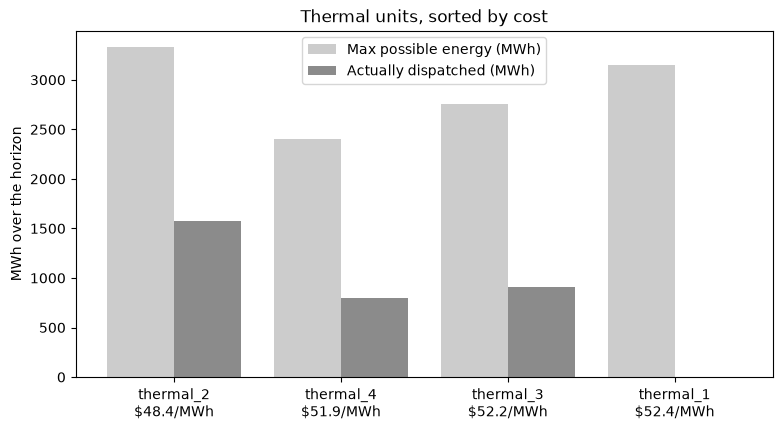

In [4]:
order = np.argsort([g.cost for g in system.thermal])
names = [system.thermal[i].name for i in order]
costs = [system.thermal[i].cost for i in order]
p_max = [system.thermal[i].p_max for i in order]
energy_dispatched = (result.thermal.sum(axis=1) * system.dt)[order]
energy_available = np.array(p_max) * system.T * system.dt

x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - 0.2, energy_available, width=0.4, color="#CCCCCC", label="Max possible energy (MWh)")
ax.bar(x + 0.2, energy_dispatched, width=0.4, color="#8B8B8B", label="Actually dispatched (MWh)")
ax.set_xticks(x)
ax.set_xticklabels([f"{n}\n${c:.1f}/MWh" for n, c in zip(names, costs)])
ax.set_ylabel("MWh over the horizon")
ax.set_title("Thermal units, sorted by cost")
ax.legend()
plt.show()

## Storage competition: willingness-to-pay decides who holds energy

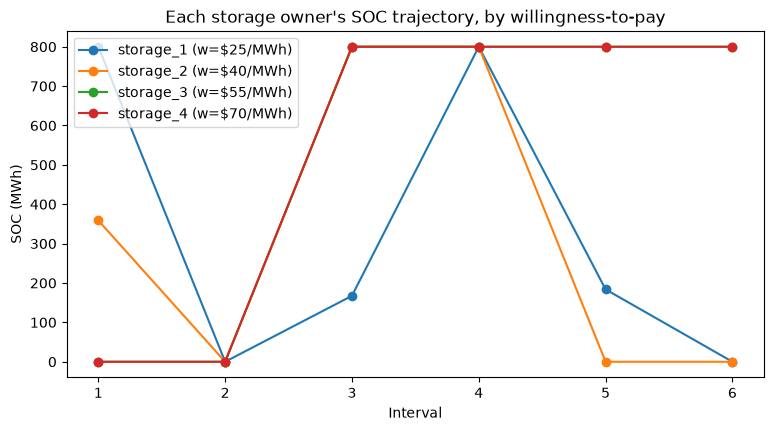

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, s in enumerate(system.storages):
    ax.plot(hours, result.soc[i], marker="o", label=f"{s.name} (w=${storage_wtp[i]:.0f}/MWh)")
ax.set_xlabel("Interval")
ax.set_ylabel("SOC (MWh)")
ax.set_title("Each storage owner's SOC trajectory, by willingness-to-pay")
ax.legend()
plt.show()

Owners valuing end-of-horizon energy above the marginal thermal cost (\$25 base
case here is roughly \$50/MWh) hold their SOC near the cap; owners valuing it below drain
back to zero exactly as in `reproduce_baldick.py`'s base vs. high-willingness-to-pay
cases -- except now four different valuations play out side by side in the same
market clearing.

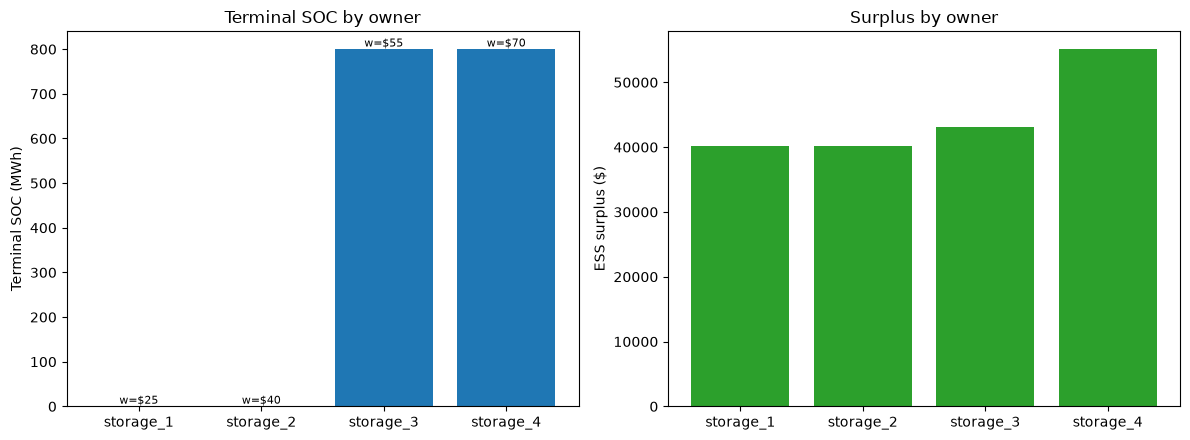

In [6]:
fig, (ax_soc, ax_surplus) = plt.subplots(1, 2, figsize=(12, 4.5))
names = [s.name for s in system.storages]

ax_soc.bar(names, result.terminal_soc, color="#1F77B4")
for i, v in enumerate(result.terminal_soc):
    ax_soc.annotate(f"w=${storage_wtp[i]:.0f}", (i, v), ha="center", va="bottom", fontsize=8)
ax_soc.set_ylabel("Terminal SOC (MWh)")
ax_soc.set_title("Terminal SOC by owner")

ax_surplus.bar(names, result.ess_surplus, color="#2CA02C")
ax_surplus.set_ylabel("ESS surplus ($)")
ax_surplus.set_title("Surplus by owner")

fig.tight_layout()
plt.show()

## Renewable owners: no price competition, just a shared allocation

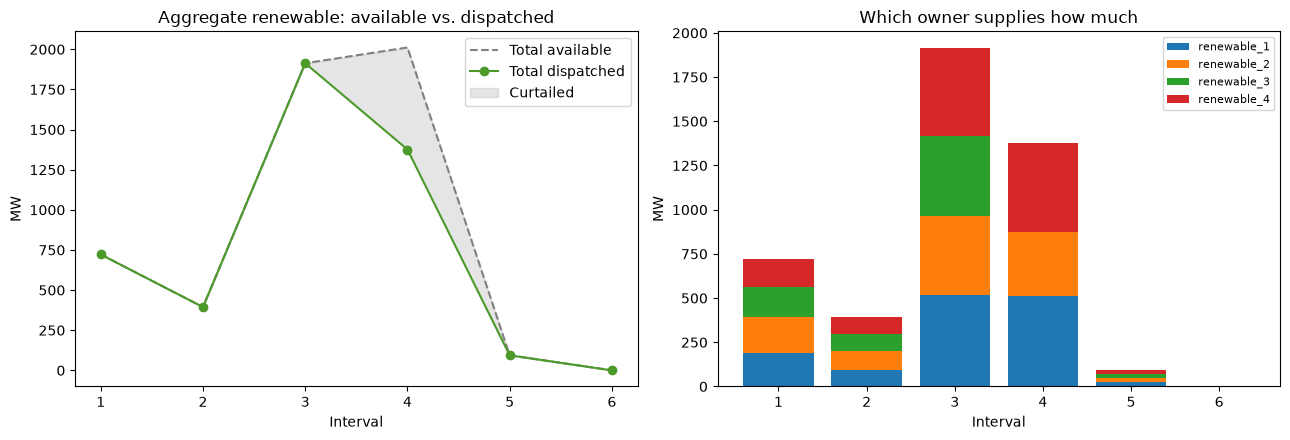

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

avail_total = np.array([r.capacity for r in system.renewables]).sum(axis=0)
dispatched_total = result.renewable.sum(axis=0)
ax1.plot(hours, avail_total, linestyle="--", color="grey", label="Total available")
ax1.plot(hours, dispatched_total, marker="o", color="#4C9A2A", label="Total dispatched")
ax1.fill_between(hours, dispatched_total, avail_total, color="grey", alpha=0.2, label="Curtailed")
ax1.set_title("Aggregate renewable: available vs. dispatched")
ax1.set_xlabel("Interval")
ax1.set_ylabel("MW")
ax1.legend()

bottom = np.zeros(system.T)
for i, r in enumerate(system.renewables):
    ax2.bar(hours, result.renewable[i], bottom=bottom, label=r.name)
    bottom += result.renewable[i]
ax2.set_title("Which owner supplies how much")
ax2.set_xlabel("Interval")
ax2.set_ylabel("MW")
ax2.legend(fontsize=8)

fig.tight_layout()
plt.show()

All four renewables offer at \$0/MWh, so the LP is indifferent about *which* one
supplies a given MW as long as the total is right and each stays within its own capacity
-- the same tied-optimum structure documented in `ROADMAP.md` for the thermal/storage
degeneracy in `reproduce_baldick.py`, now showing up between renewable owners too. The
right panel's split reflects Gurobi's particular tie-break, not something economically
meaningful about these four owners.

## System-wide dispatch stack, with clearing price

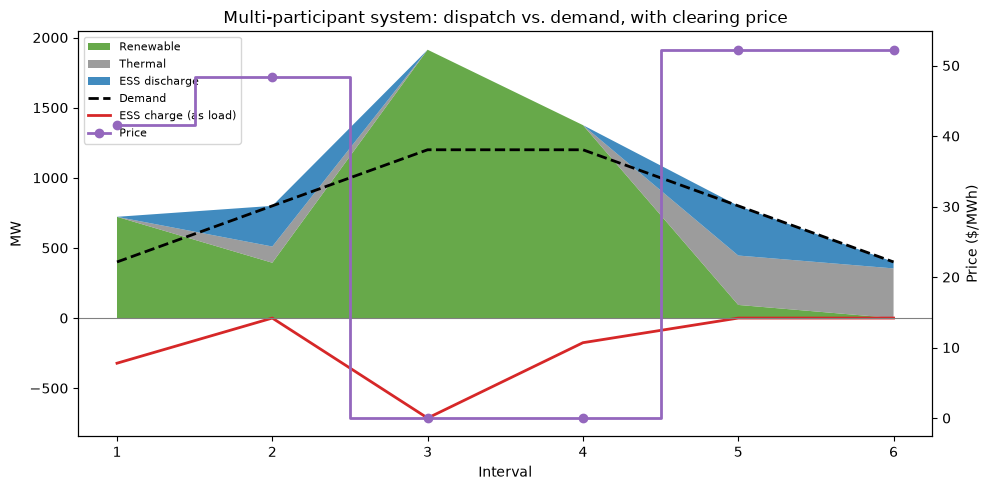

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.stackplot(
    hours,
    result.renewable.sum(axis=0),
    result.thermal.sum(axis=0),
    result.discharge.sum(axis=0),
    labels=["Renewable", "Thermal", "ESS discharge"],
    colors=["#4C9A2A", "#8B8B8B", "#1F77B4"],
    alpha=0.85,
)
ax.plot(hours, system.demand, color="black", linewidth=2, linestyle="--", label="Demand")
ax.plot(hours, -result.charge.sum(axis=0), color="#D62728", linewidth=2, label="ESS charge (as load)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Interval")
ax.set_ylabel("MW")

ax_price = ax.twinx()
ax_price.step(hours, result.price, where="mid", color="#9467BD", linewidth=2, marker="o", label="Price")
ax_price.set_ylabel("Price ($/MWh)")

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax_price.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax.set_title("Multi-participant system: dispatch vs. demand, with clearing price")
fig.tight_layout()
plt.show()

## Next steps

This is one draw from a seeded random generator (`SEED = 7` in
`Multi_Participant_Baldick.py`), not an average over scenarios -- change the seed or the
spreads (`THERMAL_COST_SPREAD`, `STORAGE_WTP`, `RENEWABLE_NOISE_FRACTION`) to see how
sensitive the merit order and storage competition results are. Turning this into a proper
controlled experiment -- sweeping the spread of storage willingness-to-pay and measuring
how surplus concentrates among high-`w` owners -- is exactly ROADMAP.md stage 5.